# S8 · Robustness and sensitivity analyses

Code: `code/si/S8_robustness.R`. Each block repeats the main model under
one change: filtered tokens, another filtering threshold, another
treatment of the nomination limit, subsamples by classroom size, sex or
grade, temporal controls, a lagged placebo, and other ways of measuring
rank.

In [ ]:
here::i_am("notebooks/si/S8_robustness.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(igraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

dyads <- dyads %>%
  mutate(class_round = paste(class_id, round, sep = "_"),
         mutual = as.integer(friendship == "Mutual"))

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

# The preferred model (sender + classroom-by-round FE, SE by classroom) for
# any outcome and right-hand side. Returns NULL when it cannot be estimated.
preferred_model <- function(data, outcome = "coop_gap", rhs = "rank_gap",
                            fixed_effects = "sender_id + class_round") {
  data <- data %>% mutate(across(any_of(c("sender_id", "class_id", "class_round", "round")), as.factor))
  quiet_felm(as.formula(paste(outcome, "~", rhs, "|", fixed_effects, "| 0 | class_id")), data)
}

# Coefficient, SE and p of one term. NA = "not estimable" (n.e.): the model
# failed, the SE is not finite, or fewer than 10 residual degrees of freedom
# remain after the fixed effects (felm's df, which is also capped at the
# number of classrooms - 1).
term_estimate <- function(model, term = "rank_gap") {
  if (is.null(model) || model$df < 10) return(tibble(estimate = NA_real_, se = NA_real_, p_value = NA_real_))
  ct <- quiet_summary(model)$coefficients
  if (!term %in% rownames(ct) || !is.finite(ct[term, "Cluster s.e."]))
    return(tibble(estimate = NA_real_, se = NA_real_, p_value = NA_real_))
  tibble(estimate = ct[term, "Estimate"], se = ct[term, "Cluster s.e."], p_value = ct[term, "Pr(>|t|)"])
}

## 8.1 Filtered tokens (Tables S25–S30, Figure S25)

These regressions use the Cooperation GAP for pairs in which both
transfers survive the null-model filter. Standard errors are in
parentheses.

### Estimates by friendship group

#### Table S25. All dyads

In [ ]:
# 8.1 The main tables again, with the null-model filtered Cooperation GAP
# (only pairs where both transfers survive the filter; see 01_build_measures.R)
filtered <- dyads %>% filter(!is.na(coop_gap_filtered))
nrow(filtered)
## [1] 4590

fe_filtered_all    <- fe_progression(filtered, outcome = "coop_gap_filtered")
fe_filtered_non    <- fe_progression(filter(filtered, friendship == "Non-friends"), outcome = "coop_gap_filtered")
fe_filtered_mutual <- fe_progression(filter(filtered, friendship == "Mutual"), outcome = "coop_gap_filtered")
fe_filtered_pooled <- fe_progression(filter(filtered, friendship %in% c("Non-friends", "Mutual")),
                                     outcome = "coop_gap_filtered", formula_rhs = "rank_gap * mutual")

regression_table(fe_filtered_all,    terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,3.093***,3.093***,3.178***,3.168***,3.426***
,(0.197),(0.469),(0.458),(0.457),(0.503)
Observations,"4,590","4,590","4,590","4,590","4,590"
R2,0.051,0.051,0.288,0.289,0.338
Adj. R2,0.051,0.042,0.134,0.125,-0.049


#### Table S26. Non-friends

In [ ]:
regression_table(fe_filtered_non,    terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,3.260***,3.260***,3.223***,3.183***,3.412***
,(0.233),(0.462),(0.496),(0.492),(0.654)
Observations,"3,302","3,302","3,302","3,302","3,302"
R2,0.056,0.056,0.331,0.333,0.413
Adj. R2,0.056,0.043,0.129,0.118,-0.085


#### Table S27. Mutual friends

In [ ]:
regression_table(fe_filtered_mutual, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,-0.593,-0.593,-0.367,-0.030,5.167
,(0.529),(0.607),(1.018),(0.978),(3.463)
Observations,548,548,548,548,548
R2,0.002,0.002,0.755,0.798,0.956
Adj. R2,0.000,-0.087,0.174,0.122,0.114


#### Table S28. Pooled non-friends and mutual friends

The interaction tests whether the slope differs for mutual friends.

In [ ]:
regression_table(fe_filtered_pooled, terms = c("rank_gap", "mutual", "rank_gap:mutual"))

row,(1),(2),(3),(4),(5)
rank_gap,3.260***,3.260***,3.261***,3.242***,3.393***
,(0.225),(0.462),(0.462),(0.460),(0.543)
mutual,-0.000,-0.000,-0.161,-0.184,-0.504*
,(0.217),(0.000),(0.126),(0.130),(0.210)
rank_gap:mutual,-3.853***,-3.853***,-3.767***,-3.778***,-4.194***
,(0.720),(0.731),(0.731),(0.736),(0.824)
Observations,"3,850","3,850","3,850","3,850","3,850"
R2,0.052,0.052,0.303,0.305,0.373
Adj. R2,0.051,0.040,0.120,0.110,-0.083


### One-sided friendship nominations

#### Table S29. Lower to higher rank

In [ ]:
filtered_asymmetric <- filtered %>%
  filter(friendship == "Sender declares") %>%
  mutate(high_to_low = as.integer(rank_gap >= 0))

fe_filtered_lh <- fe_progression(filter(filtered_asymmetric, high_to_low == 0), outcome = "coop_gap_filtered")
fe_filtered_contrast <- fe_progression(filtered_asymmetric, outcome = "coop_gap_filtered",
                                       formula_rhs = "rank_gap * high_to_low")

regression_table(fe_filtered_lh, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,4.905***,4.165*,0.685,3.022,29.704
,(1.332),(1.694),(2.408),(3.380),(NaN)
Observations,254,254,254,254,254
R2,0.051,0.229,0.822,0.915,1.000
Adj. R2,0.047,0.075,0.223,0.021,NaN


#### Table S29. Higher to lower rank

This group includes ties in Social Rank, following the rule in the main
analysis.

Specifications (4) and (5) are not estimable for this filtered sample.
The fixed effects absorb all variation in its 116 observations.

In [ ]:
filtered_high_to_low <- filter(filtered_asymmetric, high_to_low == 1)
fe_filtered_hl <- fe_progression(filtered_high_to_low, outcome = "coop_gap_filtered")

# A saturated fixed-effects design leaves no variation for the rank gap.
fixed_effects_4 <- model.matrix(~ factor(class_id) + factor(sender_id) + factor(round),
                               data = filtered_high_to_low)
fixed_effects_5 <- model.matrix(~ factor(sender_id) + factor(class_round),
                               data = filtered_high_to_low)
if (qr(fixed_effects_4)$rank == nrow(filtered_high_to_low)) fe_filtered_hl["(4)"] <- list(NULL)
if (qr(fixed_effects_5)$rank == nrow(filtered_high_to_low)) fe_filtered_hl["(5)"] <- list(NULL)

regression_table(fe_filtered_hl, terms = "rank_gap")

row,(1),(2),(3)
rank_gap,0.138,2.706,2.680
,(2.389),(2.839),(4.458)
Observations,116,116,116
R2,0.000,0.407,0.990
Adj. R2,-0.009,0.079,0.830


#### Table S30. Direct contrast between directions

In [ ]:
regression_table(fe_filtered_contrast, terms = c("rank_gap", "rank_gap:high_to_low"))

row,(1),(2),(3),(4),(5)
rank_gap,4.905***,4.506**,2.059,3.982,29.704
,(1.348),(1.652),(2.599),(2.955),(NaN)
rank_gap:high_to_low,-4.767,-3.446,0.244,-3.096,NaN
,(2.691),(3.135),(5.952),(6.676),(NaN)
Observations,370,370,370,370,370
R2,0.054,0.159,0.839,0.897,1.000
Adj. R2,0.047,0.039,0.333,0.240,NaN


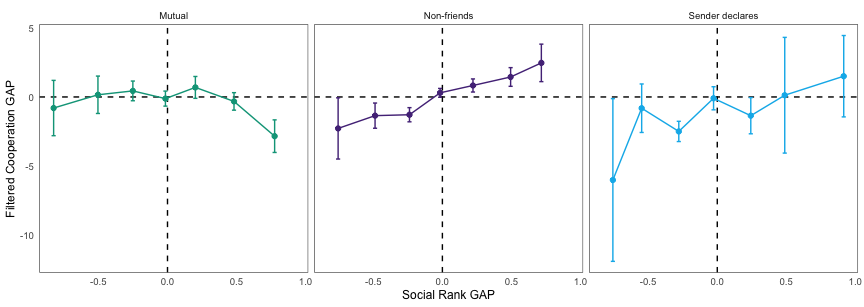

In [ ]:
# Figure S25: Figure 3 panels B and C with filtered tokens. Same binning as
# in 05_figure3_cooperation.R: per-child averages, 7 equal-width bins.
filtered_bins <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual", "Sender declares")) %>%
  group_by(friendship, sender_id) %>%
  summarise(gap = median(rank_gap),
            sent = mean(tokens_sent_filtered, na.rm = TRUE),
            received = mean(tokens_received_filtered, na.rm = TRUE),
            coop_gap = mean(coop_gap_filtered, na.rm = TRUE), .groups = "drop") %>%
  group_by(friendship) %>%
  mutate(bin = cut_interval(gap, 7)) %>%
  filter(!is.na(coop_gap)) %>%
  group_by(friendship, bin) %>%
  summarise(gap = mean(gap), n = n(),
            mean_sent = mean(sent, na.rm = TRUE), mean_received = mean(received, na.rm = TRUE),
            mean_coop_gap = mean(coop_gap), ci = 1.96 * sd(coop_gap) / sqrt(n), .groups = "drop")

figure_s25 <- ggplot(filtered_bins, aes(gap, mean_coop_gap, color = friendship)) +
  geom_hline(yintercept = 0, linetype = "dashed") + geom_vline(xintercept = 0, linetype = "dashed") +
  geom_line() + geom_point() +
  geom_errorbar(aes(ymin = mean_coop_gap - ci, ymax = mean_coop_gap + ci), width = 0.03) +
  facet_wrap(~ friendship) +
  scale_color_manual(values = c("Non-friends" = color_non_friends, Mutual = color_mutual,
                                "Sender declares" = color_asymmetric)) +
  labs(x = "Social Rank GAP", y = "Filtered Cooperation GAP") +
  theme_paper(9) + theme(strip.background = element_blank())
figure_s25

## 8.2 Filtering threshold and cutoff (Tables S31–S34)

“global” = one cutoff for all transfers (primary); “sender” = each child
keeps her own top share. n.e. (NA) marks models that cannot be estimated
(fewer than 10 residual degrees of freedom).

In [ ]:
# 8.2 Re-filter at other retention rates. "global": one cutoff for all
# transfers (the primary choice); "sender": each child keeps her own top
# share of transfers (ties and children with no variation are kept in full).
filter_at <- function(retention, scope = "global") {
  if (scope == "global") {
    cutoff <- sort(dyads$departure, decreasing = TRUE)[ceiling(retention * nrow(dyads))]
    kept <- dyads %>% mutate(keep = departure >= cutoff)
  } else {
    kept <- dyads %>%
      group_by(sender_id) %>%
      mutate(keep = departure >= quantile(departure, 1 - retention)) %>%
      ungroup()
  }
  reverse_keep <- kept %>% select(class_id, sender_id = receiver_id, receiver_id = sender_id, keep_reverse = keep)
  kept %>%
    left_join(reverse_keep, by = c("class_id", "sender_id", "receiver_id")) %>%
    mutate(coop_gap_p = if_else(keep & keep_reverse, coop_gap, NA_real_))
}

threshold_row <- function(retention, scope) {
  d <- filter_at(retention, scope)
  pairs <- d %>% filter(!is.na(coop_gap_p))
  all_fit    <- preferred_model(pairs, "coop_gap_p")
  non_fit    <- preferred_model(filter(pairs, friendship == "Non-friends"), "coop_gap_p")
  mutual_fit <- preferred_model(filter(pairs, friendship == "Mutual"), "coop_gap_p",
                                fixed_effects = "sender_id + class_id + round")
  pooled_fit <- preferred_model(filter(pairs, friendship %in% c("Non-friends", "Mutual")),
                                "coop_gap_p", rhs = "rank_gap * mutual")
  mutual_slope <- if (is.null(pooled_fit) || pooled_fit$df < 10) c(estimate = NA, se = NA) else {
    b <- coef(pooled_fit); V <- vcov(pooled_fit); w <- c(1, 0, 1)
    c(estimate = sum(w * b), se = sqrt(drop(t(w) %*% V %*% w)))
  }
  tibble(scope = scope, target = retention,
         transfers_retained = mean(d$keep), interactions = sum(d$keep),
         dyads_retained = mean(!is.na(d$coop_gap_p)), dyad_n = nrow(pairs),
         pooled_n = sum(pairs$friendship %in% c("Non-friends", "Mutual")),
         mutual_n = sum(pairs$friendship == "Mutual"),
         all = term_estimate(all_fit), non_friends = term_estimate(non_fit),
         mutual = term_estimate(mutual_fit),
         pooled_b1 = term_estimate(pooled_fit, "rank_gap"),
         pooled_b3 = term_estimate(pooled_fit, "rank_gap:mutual"),
         pooled_mutual_slope = mutual_slope[["estimate"]])
}

In [ ]:
retention_rates <- c(1, 0.7, 0.6, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05)

threshold_sensitivity <- bind_rows(
  map_dfr(retention_rates, threshold_row, scope = "global"),
  map_dfr(retention_rates, threshold_row, scope = "sender")
) %>%
  unnest(c(all, non_friends, mutual, pooled_b1, pooled_b3), names_sep = "_")

threshold_sensitivity %>%
  select(scope, target, transfers_retained, interactions, dyad_n, mutual_n,
         all_estimate, non_friends_estimate, mutual_estimate, pooled_b3_estimate) %>%
  mutate(across(where(is.double), ~ round(.x, 2)))

scope,target,transfers_retained,interactions,dyad_n,mutual_n,all_estimate,non_friends_estimate,mutual_estimate,pooled_b3_estimate
global,1.00,1.00,17804,17804,1288,2.58,2.56,1.26,-1.67
global,0.70,0.70,12465,8874,838,3.14,3.21,0.64,-2.42
global,0.60,0.60,10684,6566,684,3.28,3.16,0.90,-2.77
global,0.50,0.50,8903,4590,548,3.43,3.41,-0.03,-4.19
global,0.40,0.40,7125,2966,424,3.61,3.38,-1.02,-3.31
global,0.30,0.30,5348,1774,310,2.64,1.77,-3.52,-1.11
global,0.25,0.25,4454,1276,262,2.10,-0.23,NA,1.87
global,0.20,0.20,3564,838,208,2.59,2.81,NA,1.40
global,0.15,0.15,2677,540,148,4.27,NA,NA,NA
global,0.10,0.10,1781,284,92,NA,NA,NA,NA


## 8.3 Nomination limit (Table S35, Figure S26)

In [ ]:
# 8.3 Rebuild Social Rank with modified popularity nominations and re-run
# the main model: (i) keep at most k nominations per child and item, chosen
# at random (25 draws, median coefficient); (ii) drop the nominations of
# children who used all five on an item.
rank_gap_from <- function(positive, negative) {
  edges <- dyads %>%
    transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id),
              weight = positive - negative + 1)
  ranks <- edges %>%
    group_by(class_id) %>%
    group_modify(function(e, key) {
      pr <- page_rank(graph_from_data_frame(e %>% filter(weight > 0),
                                            vertices = data.frame(name = unique(c(e$from, e$to)))))$vector
      tibble(student_id = as.numeric(names(pr)), rank = (pr - min(pr)) / (max(pr) - min(pr)))
    }) %>% ungroup()
  rank_of <- setNames(ranks$rank, ranks$student_id)
  rank_of[as.character(dyads$sender_id)] - rank_of[as.character(dyads$receiver_id)]
}

cap_at <- function(nominations, k) {
  # for each sender, keep a random subset of at most k of her nominations
  dyads %>%
    mutate(nom = nominations, row = row_number()) %>%
    group_by(sender_id) %>%
    mutate(keep = nom == 1 & rank(runif(n()) - nom) <= k) %>%   # nominated rows first, in random order
    ungroup() %>%
    pull(keep) %>% as.integer()
}

main_with_gap <- function(gap) term_estimate(preferred_model(dyads %>% mutate(rank_gap = gap)))

set.seed(2026)
cap_draws <- map_dfr(c(3, 4), function(k) {
  map_dfr(1:25, function(draw) {
    main_with_gap(rank_gap_from(cap_at(dyads$nom_q4, k), cap_at(dyads$nom_q5, k))) %>%
      mutate(k = k, draw = draw)
  })
})

out_counts <- dyads %>% group_by(sender_id) %>% summarise(q4 = sum(nom_q4), q5 = sum(nom_q5))
reached_q4 <- out_counts$sender_id[out_counts$q4 >= 5]
reached_q5 <- out_counts$sender_id[out_counts$q5 >= 5]

table_s35 <- bind_rows(
  main_with_gap(dyads$rank_gap) %>% mutate(construction = "Baseline (all nominations)"),
  cap_draws %>% filter(k == 3) %>% summarise(across(c(estimate, se, p_value), median)) %>%
    mutate(construction = "Fixed cap k = 3 (median of 25 draws)"),
  cap_draws %>% filter(k == 4) %>% summarise(across(c(estimate, se, p_value), median)) %>%
    mutate(construction = "Fixed cap k = 4 (median of 25 draws)"),
  main_with_gap(rank_gap_from(if_else(dyads$sender_id %in% reached_q4, 0, dyads$nom_q4),
                              if_else(dyads$sender_id %in% reached_q5, 0, dyads$nom_q5))) %>%
    mutate(construction = "Exclude cap-reachers (>= 5)")
) %>% relocate(construction)

table_s35

construction,estimate,se,p_value
Baseline (all nominations),2.583957,0.2737866,0
Fixed cap k = 3 (median of 25 draws),2.573374,0.2778121,0
Fixed cap k = 4 (median of 25 draws),2.586133,0.2785232,0
Exclude cap-reachers (>= 5),2.608264,0.2880808,0


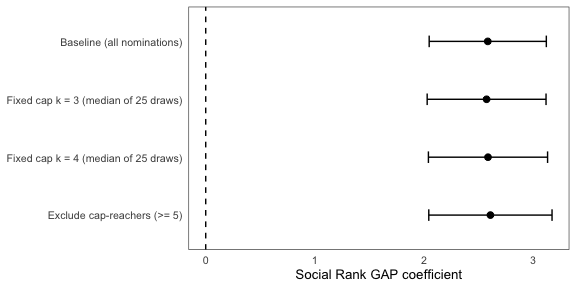

In [ ]:
figure_s26

## 8.4 Classroom size (Figure S27)

### Number of classrooms in each size group

In [ ]:
# 8.4 Does the slope differ by classroom size? Size terciles and a continuous
# interaction (the main effect of size is absorbed by the fixed effects).
dyads <- dyads %>%
  group_by(class_id) %>% mutate(class_size = n_distinct(sender_id)) %>% ungroup() %>%
  mutate(size_group = cut(class_size, c(0, 15, 21, 39), labels = c("Small (<=15)", "Medium (16-21)", "Large (>21)")))

dyads %>% distinct(class_id, size_group) %>% count(size_group)

size_group,n
Small (<=15),16
Medium (16-21),14
Large (>21),15


### Social Rank GAP slope by classroom size group

In [ ]:
size_slopes <- dyads %>%
  group_by(size_group) %>%
  group_modify(~ term_estimate(preferred_model(.x))) %>% ungroup()
size_slopes

size_group,estimate,se,p_value
Small (<=15),1.987877,0.6666323,0.0093082
Medium (16-21),2.824818,0.5507177,0.0001935
Large (>21),2.636798,0.3660777,0.0000045


### Joint test of differences across size groups

In [ ]:
size_interaction <- preferred_model(dyads, rhs = "rank_gap * size_group")
lfe::waldtest(size_interaction, grep("rank_gap:size_group", names(coef(size_interaction))))[["p.F"]]
## [1] 0.5935522

### Interaction with classroom size as a continuous measure

In [ ]:
term_estimate(preferred_model(dyads, rhs = "rank_gap * class_size"), "rank_gap:class_size")

estimate,se,p_value
0.0239172,0.0256327,0.355873


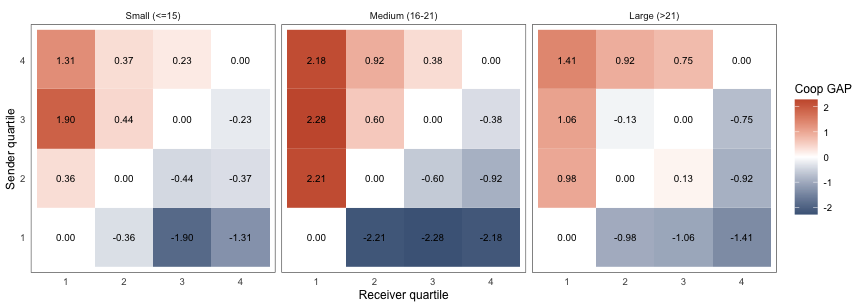

In [ ]:
quartile_cuts <- quantile(c(dyads$sender_rank, dyads$receiver_rank), c(0.25, 0.5, 0.75))
figure_s27 <- dyads %>%
  mutate(sender_q   = findInterval(sender_rank, quartile_cuts, left.open = TRUE) + 1,
         receiver_q = findInterval(receiver_rank, quartile_cuts, left.open = TRUE) + 1) %>%
  group_by(size_group, sender_q, receiver_q) %>%
  summarise(observed = mean(coop_gap), .groups = "drop") %>%
  ggplot(aes(factor(receiver_q), factor(sender_q), fill = observed)) +
  geom_tile() + geom_text(aes(label = sprintf("%.2f", observed)), size = 2.6) +
  scale_fill_gradient2(low = "#4B6587", mid = "white", high = "#C95A3A") +
  facet_wrap(~ size_group) +
  labs(x = "Receiver quartile", y = "Sender quartile", fill = "Coop GAP") +
  theme_paper(9) + theme(legend.position = "right", strip.background = element_blank())
figure_s27

## 8.5 Temporal robustness (Table S36)

In [ ]:
# 8.5 Does the slope change over the session?
#   progress_c          the sender's progress, centered (-0.5 to 0.5)
#   decile differences  receiver-minus-sender indicators of progress deciles
dyads <- dyads %>%
  group_by(sender_id) %>% arrange(round, .by_group = TRUE) %>%
  mutate(order = row_number(), progress = (order - 1) / (n() - 1),
         progress_c = progress - 0.5,
         decile = pmin(pmax(ceiling(progress * 10), 1), 10)) %>%
  ungroup()

# decile of the receiver in this same encounter
receiver_decile <- dyads %>% select(class_id, sender_id = receiver_id, receiver_id = sender_id,
                                    receiver_decile = decile)
dyads <- dyads %>% left_join(receiver_decile, by = c("class_id", "sender_id", "receiver_id"))
for (k in 2:10) {
  dyads[[paste0("decile_diff_", k)]] <- (dyads$receiver_decile == k) - (dyads$decile == k)
}
decile_controls <- paste(paste0("decile_diff_", 2:10), collapse = " + ")
non_mutual <- dyads %>% filter(friendship %in% c("Non-friends", "Mutual"))

temporal_models <- list(
  "(1) main"                    = preferred_model(dyads),
  "(2) sender linear trends"    = preferred_model(dyads, fixed_effects = "sender_id + class_round + sender_id:progress"),
  "(3) progress deciles"        = preferred_model(dyads, rhs = paste("rank_gap +", decile_controls)),
  "(4) gap x progress"          = preferred_model(dyads, rhs = "rank_gap * progress_c"),
  "(5) non-friends, x progress" = preferred_model(filter(dyads, friendship == "Non-friends"), rhs = "rank_gap * progress_c"),
  "(6) pooled"                  = preferred_model(non_mutual, rhs = "rank_gap * mutual"),
  "(7) pooled + deciles"        = preferred_model(non_mutual, rhs = paste0("rank_gap * mutual + (", decile_controls, ") * mutual")),
  "(8) pooled x progress"       = preferred_model(non_mutual, rhs = "rank_gap * mutual * progress_c")
)

table_s36 <- imap_dfr(temporal_models, function(fit, name) {
  summary(fit)$coefficients %>% as_tibble(rownames = "term") %>%
    filter(str_detect(term, "rank_gap")) %>%
    transmute(model = name, term, estimate = Estimate, se = `Cluster s.e.`, p_value = `Pr(>|t|)`, n = fit$N)
})
table_s36 %>% mutate(across(where(is.double), ~ round(.x, 3)))

model,term,estimate,se,p_value,n
(1) main,rank_gap,2.584,0.274,0.000,17804
(2) sender linear trends,rank_gap,2.551,0.271,0.000,17804
(3) progress deciles,rank_gap,2.581,0.275,0.000,17804
(4) gap x progress,rank_gap,2.567,0.270,0.000,17804
(4) gap x progress,rank_gap:progress_c,0.598,0.478,0.217,17804
"(5) non-friends, x progress",rank_gap,2.532,0.275,0.000,13916
"(5) non-friends, x progress",rank_gap:progress_c,0.534,0.582,0.364,13916
(6) pooled,rank_gap,2.592,0.267,0.000,15204
(6) pooled,rank_gap:mutual,-1.674,0.557,0.004,15204
(7) pooled + deciles,rank_gap,2.586,0.267,0.000,15204


## 8.6 Lagged placebo (Tables S37–S38)

### Table S37. Previous decision’s rank gap in the full sample

In [ ]:
# 8.6 Placebo: the rank gap the child faced in her previous decision should
# not predict today's Cooperation GAP once sender and class-round FE are in.
dyads <- dyads %>%
  group_by(sender_id) %>% arrange(order, .by_group = TRUE) %>%
  mutate(lagged_rank_gap = lag(rank_gap)) %>% ungroup()

lagged <- dyads %>% filter(!is.na(lagged_rank_gap))
fe_placebo <- fe_progression(lagged, formula_rhs = "lagged_rank_gap")
regression_table(fe_placebo, terms = "lagged_rank_gap")

row,(1),(2),(3),(4),(5)
lagged_rank_gap,1.512***,1.512***,0.290,0.290,0.295
,(0.103),(0.181),(0.288),(0.288),(0.290)
Observations,"16,945","16,945","16,945","16,945","16,945"
R2,0.013,0.013,0.259,0.259,0.264
Adj. R2,0.013,0.010,0.219,0.217,0.174


### Table S38. Placebo estimates by sample and token filter

In [ ]:
placebo_samples <- list(
  "All"                    = list(lagged, "coop_gap"),
  "All (filtered)"         = list(lagged, "coop_gap_filtered"),
  "Mutual"                 = list(filter(lagged, friendship == "Mutual"), "coop_gap"),
  "Mutual (filtered)"      = list(filter(lagged, friendship == "Mutual"), "coop_gap_filtered"),
  "Non-friends"            = list(filter(lagged, friendship == "Non-friends"), "coop_gap"),
  "Non-friends (filtered)" = list(filter(lagged, friendship == "Non-friends"), "coop_gap_filtered")
)
table_s38 <- imap_dfr(placebo_samples, function(s, name) {
  d <- s[[1]] %>% filter(!is.na(.data[[s[[2]]]]))
  fit <- preferred_model(d, outcome = s[[2]], rhs = "lagged_rank_gap")
  term_estimate(fit, "lagged_rank_gap") %>% mutate(sample = name, n = nrow(d), .before = 1)
})
table_s38

sample,n,estimate,se,p_value
All,16945,0.2952552,0.2897583,0.3137873
All (filtered),4358,-0.7383623,0.3923966,0.0665060
Mutual,1228,0.8190812,1.2947451,0.5302562
Mutual (filtered),541,7.2978025,3.6523657,0.0562658
Non-friends,13245,0.2427858,0.3085534,0.4355866
Non-friends (filtered),3116,-0.6471377,0.6039127,0.2897537


## 8.7 Sex and grade level (Tables S39–S50)

The code builds all twelve subgroup tables. The preview below shows the
sex specifications for all dyads using observed tokens. Run the script
to export the full set.

In [ ]:
# 8.7 Does the slope differ by the children's sex or grade level?
# Classroom + sender FE, SE by classroom (sender sex is constant within
# sender, so only its interactions can be estimated).
dyads <- dyads %>%
  left_join(students %>% select(sender_id = student_id, sender_female = female, grade), by = "sender_id") %>%
  left_join(students %>% select(receiver_id = student_id, receiver_female = female), by = "receiver_id")

sex_models <- function(data, outcome) {
  data <- data %>% filter(!is.na(.data[[outcome]]))
  fe <- "class_id + sender_id"
  list(
    "(1) all"                 = preferred_model(data, outcome, "rank_gap", fe),
    "(2) + receiver female"   = preferred_model(data, outcome, "rank_gap + receiver_female", fe),
    "(3) sex interactions"    = preferred_model(data, outcome, "rank_gap * sender_female * receiver_female", fe),
    "(4) girls"               = preferred_model(filter(data, sender_female == 1), outcome, "rank_gap", fe),
    "(5) girls + receiver F"  = preferred_model(filter(data, sender_female == 1), outcome, "rank_gap + receiver_female", fe),
    "(6) boys"                = preferred_model(filter(data, sender_female == 0), outcome, "rank_gap", fe),
    "(7) boys + receiver F"   = preferred_model(filter(data, sender_female == 0), outcome, "rank_gap + receiver_female", fe)
  )
}

grade_models <- function(data, outcome) {
  data <- data %>% filter(!is.na(.data[[outcome]])) %>% mutate(grade = factor(grade))
  fe <- "class_id + sender_id"
  list(
    "(1) all"               = preferred_model(data, outcome, "rank_gap", fe),
    "(2) gap x grade"       = preferred_model(data, outcome, "rank_gap + rank_gap:grade", fe),
    "(3) 3rd grade"         = preferred_model(filter(data, grade == 3), outcome, "rank_gap", fe),
    "(4) 4th grade"         = preferred_model(filter(data, grade == 4), outcome, "rank_gap", fe),
    "(5) 5th grade"         = preferred_model(filter(data, grade == 5), outcome, "rank_gap", fe)
  )
}

subgroup_tables <- expand_grid(by = c("sex", "grade"),
                               sample = c("All dyads", "Mutual friends", "Non-friends"),
                               outcome = c("coop_gap", "coop_gap_filtered")) %>%
  mutate(table = pmap(list(by, sample, outcome), function(by, sample, outcome) {
    d <- switch(sample, "All dyads" = dyads,
                "Mutual friends" = filter(dyads, friendship == "Mutual"),
                "Non-friends" = filter(dyads, friendship == "Non-friends"))
    models <- if (by == "sex") sex_models(d, outcome) else grade_models(d, outcome)
    regression_table(compact(models))
  }))

# for example, sex, all dyads, observed tokens
subgroup_tables$table[[1]]

row,(1) all,(2) + receiver female,(3) sex interactions,(4) girls,(5) girls + receiver F,(6) boys,(7) boys + receiver F
rank_gap,2.587***,2.592***,2.162***,2.818***,2.822***,2.271***,2.277***
,(0.272),(0.270),(0.395),(0.288),(0.287),(0.373),(0.371)
receiver_female,,-0.095,-0.112,,-0.079,,-0.109
,,(0.258),(0.255),,(0.266),,(0.254)
sender_female,,,NaN,,,,
,,,(0.000),,,,
rank_gap:sender_female,,,0.566,,,,
,,,(0.447),,,,
rank_gap:receiver_female,,,0.321,,,,
,,,(0.348),,,,


## 8.8 Alternative Social Rank constructions (Figure S28)

measure,All dyads,Non-friends,Mutual friends
Social Rank (primary),2.583957,2.561512,1.0692579
Net popularity nominations,2.681388,2.628095,1.8536507
Signed in-PN centrality,2.651142,2.587113,1.6390939
Positive PageRank minus negative indegree,2.467239,2.417555,1.5936074
Two-layer PageRank,2.654337,2.623596,1.5537075
Positive-only PageRank,1.420378,1.387366,0.6653481


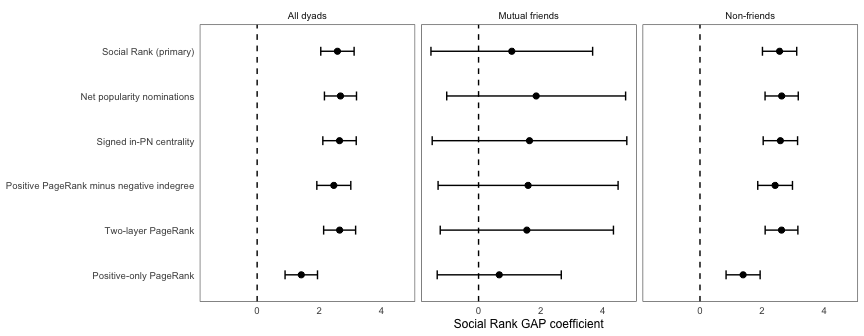

In [ ]:
# 8.8 The preferred model with the rank gap from each alternative
# construction of Social Rank (built in S4)
alternative_ranks <- read_csv(here("data", "generated", "alternative_ranks.csv"), show_col_types = FALSE)
alternative_labels <- c(social_rank = "Social Rank (primary)",
                        rank_net_nominations = "Net popularity nominations",
                        rank_pn_centrality   = "Signed in-PN centrality",
                        rank_pr_minus_neg_in = "Positive PageRank minus negative indegree",
                        rank_two_layer       = "Two-layer PageRank",
                        rank_positive_only   = "Positive-only PageRank")

gap_with <- function(measure) {
  r <- setNames(alternative_ranks[[measure]], alternative_ranks$student_id)
  r[as.character(dyads$sender_id)] - r[as.character(dyads$receiver_id)]
}

rank_robustness <- expand_grid(measure = names(alternative_labels),
                               sample = c("All dyads", "Non-friends", "Mutual friends")) %>%
  mutate(result = map2(measure, sample, function(m, s) {
    d <- dyads %>% mutate(rank_gap = gap_with(m))
    d <- switch(s, "All dyads" = d, "Non-friends" = filter(d, friendship == "Non-friends"),
                "Mutual friends" = filter(d, friendship == "Mutual"))
    term_estimate(preferred_model(d))
  })) %>%
  unnest(result) %>%
  mutate(measure = factor(alternative_labels[measure], levels = rev(alternative_labels)))

rank_robustness %>% select(measure, sample, estimate) %>%
  pivot_wider(names_from = sample, values_from = estimate)

## 8.9 Rank from affiliation networks (Table S51)

### Table S51. Regression estimates using affiliation-based ranks

In [ ]:
# 8.9 Rank from affiliation networks instead of popularity: PageRank of
# "most like to hang out" (Q1), Q1 minus "least like to hang out" (Q2)
# (standardized PageRanks), and PageRank of best friends (Q3)
pagerank_of <- function(nominations) {
  dyads %>%
    transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id), w = nominations) %>%
    group_by(class_id) %>%
    group_modify(function(e, key) {
      pr <- page_rank(graph_from_data_frame(e %>% filter(w > 0) %>% select(from, to),
                                            vertices = data.frame(name = unique(c(e$from, e$to)))))$vector
      tibble(student_id = as.numeric(names(pr)), pr = pr)
    }) %>% ungroup()
}

z <- function(x) (x - mean(x)) / sd(x)
affiliation_ranks <- pagerank_of(dyads$nom_q1) %>% rename(pr_q1 = pr) %>%
  left_join(pagerank_of(dyads$nom_q2) %>% rename(pr_q2 = pr), by = c("class_id", "student_id")) %>%
  left_join(pagerank_of(dyads$nom_q3) %>% rename(pr_q3 = pr), by = c("class_id", "student_id")) %>%
  group_by(class_id) %>%
  mutate(rank_hangout        = (pr_q1 - min(pr_q1)) / (max(pr_q1) - min(pr_q1)),
         rank_hangout_minus  = { x <- z(pr_q1) - z(pr_q2); (x - min(x)) / (max(x) - min(x)) },
         rank_best_friend    = (pr_q3 - min(pr_q3)) / (max(pr_q3) - min(pr_q3))) %>%
  ungroup() %>%
  left_join(students %>% select(student_id, social_rank), by = "student_id")

affiliation_labels <- c(social_rank = "Pop. Social Rank (primary)",
                        rank_hangout = "Most-like-to-hang-out PageRank",
                        rank_hangout_minus = "Most-minus-least hang-out PageRank",
                        rank_best_friend = "Best-friend PageRank")

table_s51 <- expand_grid(measure = names(affiliation_labels),
                         sample = c("All dyads", "Non-friends", "Mutual friends")) %>%
  mutate(result = map2(measure, sample, function(m, s) {
    r <- setNames(affiliation_ranks[[m]], affiliation_ranks$student_id)
    d <- dyads %>% mutate(rank_gap = r[as.character(sender_id)] - r[as.character(receiver_id)])
    d <- switch(s, "All dyads" = d, "Non-friends" = filter(d, friendship == "Non-friends"),
                "Mutual friends" = filter(d, friendship == "Mutual"))
    term_estimate(preferred_model(d)) %>% mutate(sd_gap = sd(d$rank_gap))
  })) %>%
  unnest(result) %>%
  mutate(measure = affiliation_labels[measure])

table_s51 %>%
  mutate(cell = sprintf("%.3f%s (%.3f)", estimate, stars(p_value), se)) %>%
  select(measure, sample, cell) %>%
  pivot_wider(names_from = sample, values_from = cell)

measure,All dyads,Non-friends,Mutual friends
Pop. Social Rank (primary),2.584*** (0.274),2.562*** (0.281),1.069 (1.327)
Most-like-to-hang-out PageRank,1.279*** (0.267),1.117*** (0.284),-0.887 (1.178)
Most-minus-least hang-out PageRank,1.492*** (0.294),1.345*** (0.300),-1.275 (1.715)
Best-friend PageRank,1.286*** (0.302),1.179** (0.337),1.617 (1.452)


### Agreement with the popularity-based Social Rank

Each entry is the median of the classroom-level Spearman correlations.

In [ ]:
# agreement with the primary rank (median within-class Spearman)
affiliation_ranks %>%
  group_by(class_id) %>%
  summarise(across(c(rank_hangout, rank_hangout_minus, rank_best_friend),
                   ~ cor(.x, social_rank, method = "spearman"))) %>%
  summarise(across(-class_id, median))

rank_hangout,rank_hangout_minus,rank_best_friend
0.4942252,0.4899733,0.5152298


In [ ]:
save_table(regression_table(fe_filtered_all, terms = "rank_gap"),    "S8_table_s25_filtered_all")
save_table(regression_table(fe_filtered_non, terms = "rank_gap"),    "S8_table_s26_filtered_non_friends")
save_table(regression_table(fe_filtered_mutual, terms = "rank_gap"), "S8_table_s27_filtered_mutual")
save_table(regression_table(fe_filtered_pooled, terms = c("rank_gap", "mutual", "rank_gap:mutual")), "S8_table_s28_filtered_pooled")
save_table(regression_table(fe_filtered_lh, terms = "rank_gap"),     "S8_table_s29_filtered_low_to_high")
save_table(regression_table(fe_filtered_hl, terms = "rank_gap"),     "S8_table_s29_filtered_high_to_low")
save_table(regression_table(fe_filtered_contrast, terms = c("rank_gap", "rank_gap:high_to_low")), "S8_table_s30_filtered_contrast")
save_table(threshold_sensitivity, "S8_tables_s31_s34_thresholds")
save_table(table_s35, "S8_table_s35_nomination_cap")
save_table(size_slopes, "S8_class_size_slopes")
save_table(table_s36, "S8_table_s36_temporal")
save_table(regression_table(fe_placebo, terms = "lagged_rank_gap"), "S8_table_s37_placebo")
save_table(table_s38, "S8_table_s38_placebo_samples")
pwalk(subgroup_tables, function(by, sample, outcome, table) {
  save_table(table, paste("S8_subgroup", by, str_replace_all(tolower(sample), "[^a-z]+", "_"), outcome, sep = "_"))
})
save_table(rank_robustness, "S8_rank_constructions")
save_table(table_s51, "S8_table_s51_affiliation_ranks")
save_si_figure(figure_s25, "S8_figure_s25_filtered", 9, 3.2)
save_si_figure(figure_s26, "S8_figure_s26_nomination_cap", 6, 3)
save_si_figure(figure_s27, "S8_figure_s27_class_size", 9, 3.2)
save_si_figure(figure_s28, "S8_figure_s28_rank_constructions", 9, 3.5)